In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
data = pd.read_csv('data.csv')


In [3]:
print(data)

     SAT   GPA
0   1714  2.40
1   1664  2.52
2   1760  2.54
3   1685  2.74
4   1693  2.83
..   ...   ...
79  1936  3.71
80  1810  3.71
81  1987  3.73
82  1962  3.76
83  2050  3.81

[84 rows x 2 columns]


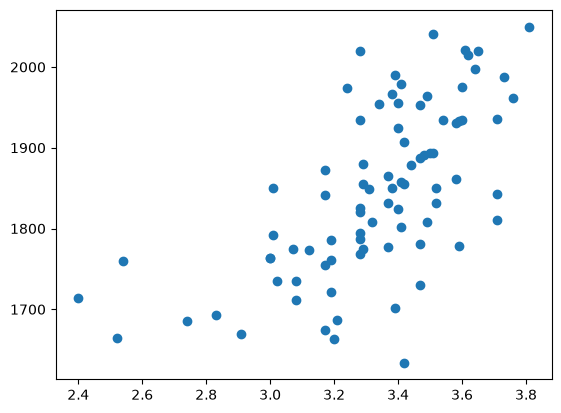

In [4]:
plt.plot(data.GPA, data.SAT, 'o')

In [5]:
def mean_squared_error(m, b, points):
    total_error = 0
    for i in range(len(points)):
        x = points.iloc[i].GPA
        y = points.iloc[i].SAT
        total_error += (y - (m * x + b)) ** 2
    total_error / float(len(points))

## Gradient Descent
$E = \frac{1}{n} \sum_{i=1}^{n}(y_i - \hat{y_i})^2$
  
where
$\hat{y_i} = mx_i + b$
so, 

$\frac{\partial E}{\partial m} = -\frac{2}{n} x_i \sum_{i=1}^{n}(y-(mx_i + b))$ and

$\frac{\partial E}{\partial b} = \frac{2}{n} \sum_{i=1}^{n}(mx_i + b - y)$



In [6]:
def gradient_descent(m_now, b_now, points, L):
    m_gradient = 0
    b_gradient = 0
    
    n = len(points)

    for i in range(n):
        x = points.iloc[i].GPA
        y = points.iloc[i].SAT

        m_gradient += -(2/n) * x * (y - (m_now * x + b_now))
        b_gradient += -(2/n) * (y - (m_now * x + b_now))
    m = m_now - m_gradient * L
    b = b_now - b_gradient * L
    return m, b

477.47693105531 250.49606938851787


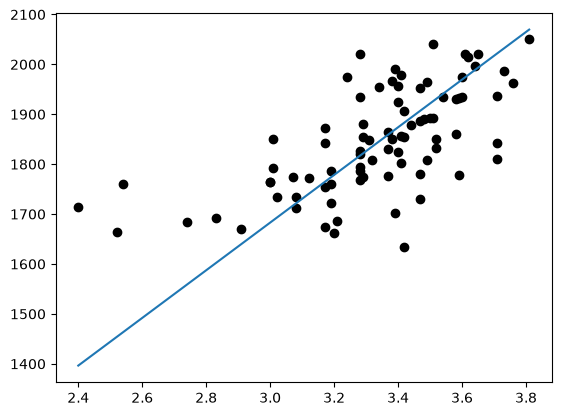

In [7]:
m = 0
b = 0
L = 0.005
epochs = 2000
for i in range(epochs):
    m, b = gradient_descent(m, b, data, L)
print(m, b)
plt.scatter(data.GPA, data.SAT, color="black")
xs = np.linspace(data.GPA.min(), data.GPA.max(), 100)
plt.plot(xs, m * xs + b)
plt.show()
#plt.plot(list(range(2, 4)), [m * x + b for x in range(2, 4)])
#plt.show